# 🏠 مشروع Data Science كامل: توقع أسعار المنازل

## المرحلة 1: فهم المشكلة
**السؤال**: هل نستطيع التنبؤ بسعر بيع المنزل من خصائصه؟

- **المتغير المستهدف**: `SalePrice` (سعر المنزل بالدولار)
- **البيانات**: 1460 منزل للتدريب (مع السعر) + 1459 منزل للتنبؤ (test)
- **المقياس**: RMSE على لوغاريتم السعر (مقياس مسابقة Kaggle)

**خطوات المشروع**: استكشاف ← تنظيف ← هندسة ميزات ← نماذج ← تقييم ← تنبؤ نهائي

> ⚠️ شغّل هذا الـ Notebook من مجلد المشروع حيث توجد ملفات train.csv و test.csv

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import joblib

pd.set_option("display.max_columns", 100)

## المرحلة 2: استكشاف البيانات (EDA)
نلقي نظرة على شكل البيانات، القيم الناقصة، وتوزيع السعر المستهدف.

In [21]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("train:", train.shape, "| test:", test.shape)
train.head()

train: (1460, 81) | test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [22]:
train["SalePrice"].describe().round(0)

count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64

In [9]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing.head(15)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
dtype: int64

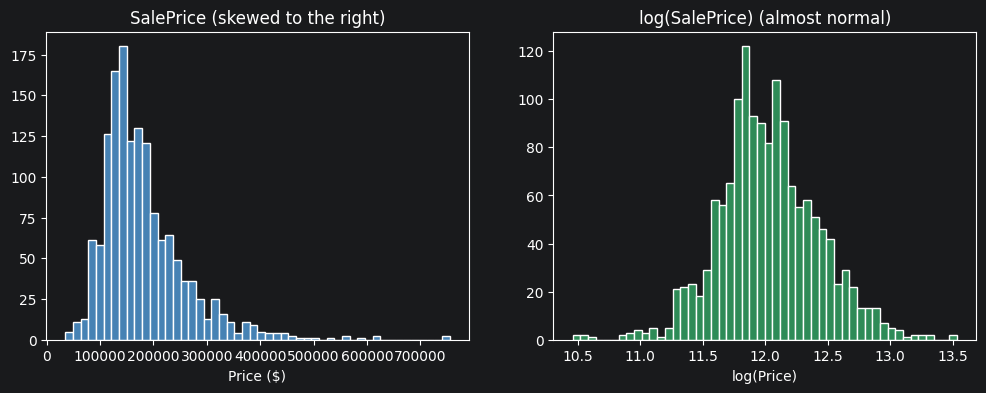

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train["SalePrice"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("SalePrice (skewed to the right)")
axes[0].set_xlabel("Price ($)")
axes[1].hist(np.log1p(train["SalePrice"]), bins=50, color="seagreen", edgecolor="white")
axes[1].set_title("log(SalePrice) (almost normal)")
axes[1].set_xlabel("log(Price)")
plt.show()

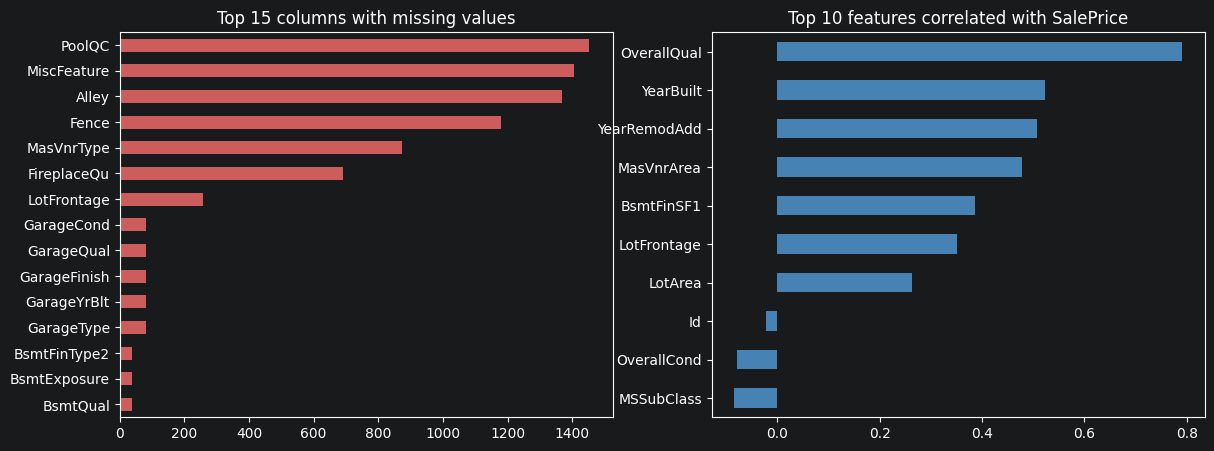

Most correlated features:
Id            -0.02
MSSubClass    -0.08
LotFrontage    0.35
LotArea        0.26
OverallQual    0.79
Name: SalePrice, dtype: float64


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

missing.head(15).sort_values().plot(kind="barh", color="indianred", ax=axes[0])
axes[0].set_title("Top 15 columns with missing values")

corr = train.select_dtypes(include=np.number).corr()["SalePrice"].drop("SalePrice")
corr.head(10).sort_values().plot(kind="barh", color="steelblue", ax=axes[1])
axes[1].set_title("Top 10 features correlated with SalePrice")
plt.show()

print("Most correlated features:")
print(corr.head(5).round(2))

## المرحلة 3: تنظيف البيانات
1. نحذف الأعمدة التي فيها أكثر من **40% قيم ناقصة** (مثل PoolQC و Alley)
2. القيم الناقصة: الرقمية نعبئها بـ **الوسيط**، والنصية بكلمة **"Missing"**
   (لا نستخدم "None" لأن pandas يقرأها كقيمة ناقصة من جديد عند فتح CSV)
3. نحذف **حالتين شاذتين**: بيوت ضخمة جداً (>4000 قدم²) بسعر منخفض جداً

In [23]:
# 1) drop columns with too many missing values
too_missing = [c for c in train.columns if train[c].isnull().mean() > 0.4]
train = train.drop(columns=too_missing)
test = test.drop(columns=too_missing)
print("Dropped columns:", too_missing)

# 2) fill remaining missing values
def fill_missing(df):
    for col in df.columns:
        if col == "SalePrice":
            continue
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna("Missing")
    return df

train = fill_missing(train)
test = fill_missing(test)
print("Missing values left:", int(train.isnull().sum().sum()), "/", int(test.isnull().sum().sum()))

# 3) remove obvious outliers (only in train)
before = len(train)
train = train[~((train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000))]
print("Outlier rows removed:", before - len(train))

Dropped columns: ['Alley', 'MasVnrType', 'FireplaceQu', 'PoolQC', 'Fence', 'MiscFeature']
Missing values left: 0 / 0
Outlier rows removed: 2


## المرحلة 4: هندسة الميزات + الترميز
- ننشئ **أعمدة جديدة مفيدة** من الموجودة (المساحة الكلية، عدد الحمامات، عمر المنزل...)
- نحول الأعمدة النصية لأرقام بـ **One-Hot Encoding** (نطبقها على train و test معاً حتى يخرجا بنفس الأعمدة)
- نحوّل السعر إلى **لوغاريتم** لأن توزيعه ملتوٍ (يحسّن دقة النموذج كثيراً)

In [24]:
def add_features(df):
    df = df.copy()
    df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
    df["TotalBath"] = df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
    df["YearsSinceRemodel"] = df["YrSold"] - df["YearRemodAdd"]
    df["HasPool"] = (df["PoolArea"] > 0).astype(int)
    df["HasFireplace"] = (df["Fireplaces"] > 0).astype(int)
    df["HasGarage"] = (df["GarageArea"] > 0).astype(int)
    return df

train = add_features(train)
test = add_features(test)

# one-hot encoding on train + test together
test_ids = test["Id"]
X_all = pd.concat(
    [train.drop(columns=["Id", "SalePrice"]), test.drop(columns=["Id"])],
    axis=0, ignore_index=True,
)
X_all = pd.get_dummies(X_all)

X_train = X_all.iloc[: len(train)]
X_test = X_all.iloc[len(train):]
y = np.log1p(train["SalePrice"])   # log of the price

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (1458, 289) | X_test: (1459, 289)


## المرحلة 5: بناء النماذج
نجرب **3 نماذج بسيطة** ونقارنها بـ Cross-Validation (5 مجموعات) بمقياس RMSE على لوغاريتم السعر — الأقل أفضل.

In [14]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, random_state=42),
}

results = {}
for name, model in models.items():
    scores = -cross_val_score(model, X_train, y, cv=5, scoring="neg_root_mean_squared_error")
    results[name] = scores.mean()
    print(f"{name:20s} CV RMSE = {scores.mean():.4f}")

best_name = min(results, key=results.get)
print("\nBest model:", best_name)

Linear Regression    CV RMSE = 0.1259
Random Forest        CV RMSE = 0.1362
Gradient Boosting    CV RMSE = 0.1191

Best model: Gradient Boosting


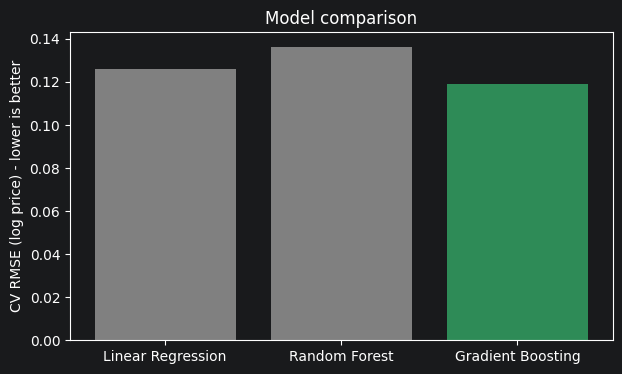

Saved best_model.pkl


In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(results.keys(), results.values(), color="gray")
ax.bar(best_name, results[best_name], color="seagreen")
ax.set_ylabel("CV RMSE (log price) - lower is better")
ax.set_title("Model comparison")
plt.show()

# train the best model on ALL the training data and save it
best_model = models[best_name]
best_model.fit(X_train, y)
joblib.dump(best_model, "best_model.pkl")
print("Saved best_model.pkl")

## المرحلة 6: تقييم النموذج الأفضل
نختبره على **20% من البيانات لم يرها أبداً**: نحسب الخطأ بالدولار و R²، ونرسم الحقيقي مقابل المتوقع وأهم الميزات.

In [16]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y, test_size=0.2, random_state=42)

model = joblib.load("best_model.pkl")   # fresh copy so we do not touch the full-data model
model.fit(X_tr, y_tr)

pred_price = np.expm1(model.predict(X_val))   # back to real dollars
true_price = np.expm1(y_val)

rmse = np.sqrt(mean_squared_error(true_price, pred_price))
r2 = r2_score(true_price, pred_price)
print(f"RMSE (real dollars) = ${rmse:,.0f}")
print(f"R2 score            = {r2:.3f}")

RMSE (real dollars) = $19,305
R2 score            = 0.933


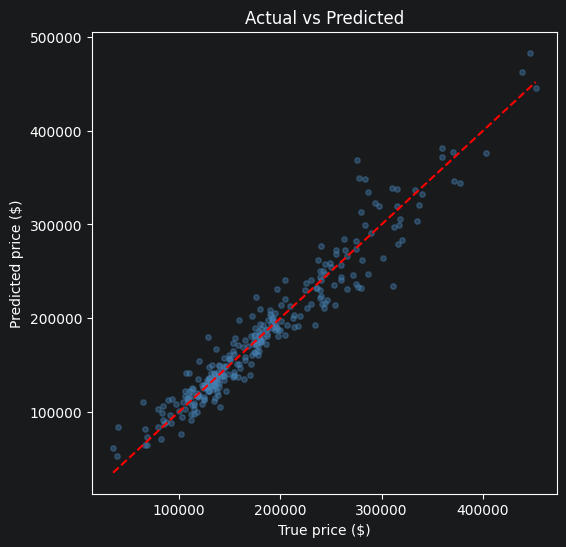

In [17]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(true_price, pred_price, alpha=0.4, s=15, color="steelblue")
lims = [true_price.min(), true_price.max()]
ax.plot(lims, lims, color="red", linestyle="--")
ax.set_xlabel("True price ($)")
ax.set_ylabel("Predicted price ($)")
ax.set_title("Actual vs Predicted")
plt.show()

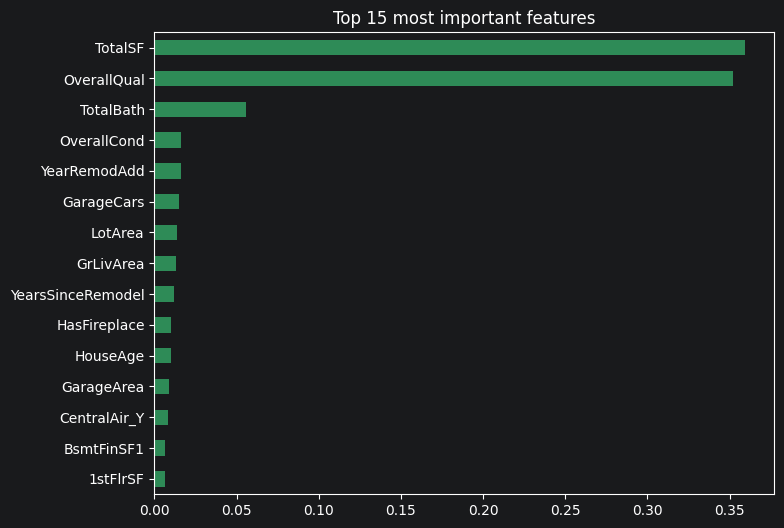

TotalSF         0.359342
OverallQual     0.352139
TotalBath       0.055725
OverallCond     0.016303
YearRemodAdd    0.015953
dtype: float64

In [18]:
importances = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
importances.head(15).sort_values().plot(kind="barh", color="seagreen", ax=ax)
ax.set_title("Top 15 most important features")
plt.show()

importances.head(5)

## المرحلة 7: التنبؤ النهائي
نستخدم النموذج المدرب على **كل** البيانات للتنبؤ بأسعار 1459 منزلاً في test.csv وننتج `submission.csv`.

In [19]:
pred_log = best_model.predict(X_test)
submission = pd.DataFrame({
    "Id": test_ids,
    "SalePrice": np.expm1(pred_log).round(0).astype(int),
})
submission.to_csv("submission.csv", index=False)
print("Houses predicted:", len(submission))
submission.head(10)

Houses predicted: 1459


,Id,SalePrice
0,1461,124874
1,1462,162758
2,1463,183502
3,1464,191422
4,1465,192263
5,1466,172425
6,1467,180277
7,1468,166726
8,1469,186551
9,1470,123999


## الخلاصة

| النموذج | CV RMSE (الأقل أفضل) |
|---|---|
| Linear Regression | 0.1259 |
| Random Forest | 0.1362 |
| **Gradient Boosting (الأفضل)** | **0.1191** |

- دقة النموذج الأفضل على بيانات لم يرها: **خطأ ≈ 19,300 دولار** و **R² = 0.93**
- أهم عوامل السعر: المساحة الكلية `TotalSF` ← الجودة `OverallQual` ← عدد الحمامات
- الملف النهائي: **submission.csv** جاهز للرفع على Kaggle

**أفكار للتطوير**: تجربة XGBoost / LightGBM، البحث عن أفضل الإعدادات (Grid Search)، ودمج تنبؤات عدة نماذج (Ensembling).